questo notebook contiene tutte le prove di test per ottimizzare gli iperparametri per le sessioni di training con PPR.
in genere, considerano sempre lo stesso env con iperparametri diversi

In [ ]:
# import delle librerie completo
import numpy as np
import matplotlib.pyplot as plt
import torch


from Function_Library import *
from Environments import *
from Agent_Torch import *

import json
import copy
import os
import time
import gc


# Training test con PPR 


## test: p=0.003[0.001] | $\psi$ 0.8 --> 0.02 in 40000

In [ ]:
# primo test di allenamento dell'agente tramite PPR su un ambiente con rumore p 0.003,
# con una libreria basata su [0.001]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "max_episode": 15000,
                "max_steps_per_episode": 1000,
                "eary_stopping": True,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.003,            # mod: 0.003
                    "p_meas": 0.003,            # mod: 0.003
                    "success_threshold": 1450,   # imposto circa la vita media ottenuta by scratch con p 0.003
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.8,             # aggiungo i parametri per PPR 
                    "final_psi": 0.02,
                    "ppr_fraction": 40000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# libreria di policy per PPR
model_paths = [r'runs\DDQN_d5_p0.001_20251010-121427\checkpoints\best_policy_net.pth']
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

Library creata con 1 modelli.


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs\DDQN_PPR_d5_p0.003_20251013-002132

---------------------------------
Step : 19420/1000000
Episode : 500
Episode Step : 34 with 17 "reuse" actions
Episode Reward : 18.0
Avg Reward (Last 500 Ep) : 19.02
Best Avg Reward : -inf
Episode Lifetime : 110
Avg Lifetime (Last 500 Ep) : 146.29
Best Avg Lifetime : -inf
Success threshold : 1450
Patience Counter : 0/1000
Metrics : Loss: 0.1103, Epsilon: 0.7462, Psi: 0.4213
Total Training Time : 255.94s
---------------------------------
                                  
*** Nuovo Best Model salvato! Avg Lifetime: 146.32 ***

---------------------------------
Step : 22001/1000000
Episode : 600
Episode Step : 5 with 1 "reuse" actions
Episode Reward : 2.0
Avg Reward (Last 500 Ep) : 13.35
Best Avg Reward : 19.03
Episode Lifetime : 25
Avg Lifetime (Last 500 Ep) : 108.68
Best Avg Lifetime : 146.32
Success threshold : 1450
Patience Counter : 0/1000
Metrics : Loss: 0.0720, Epsilon: 0.7125, Psi: 0.3

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

4 ore e 8 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.003_20251013-002132\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]
print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.003_20251013-002132\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 5057
numero step totali : 945854
best avg lifetime (rolling lenght 500) : 1782.79
----------------------------------------------------------


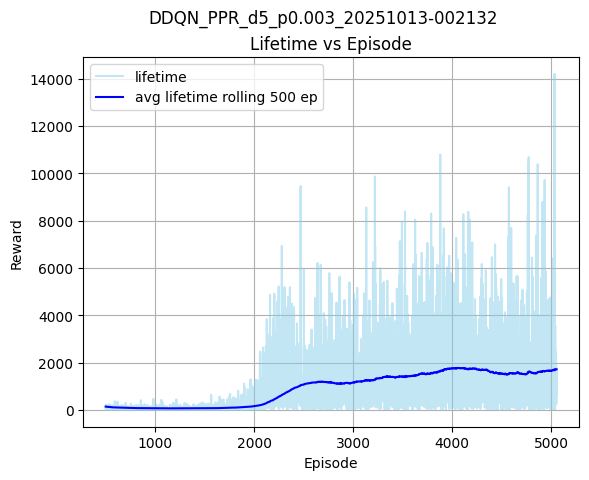

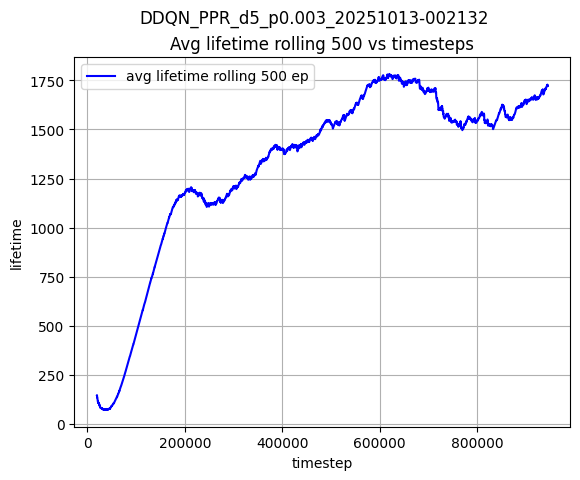

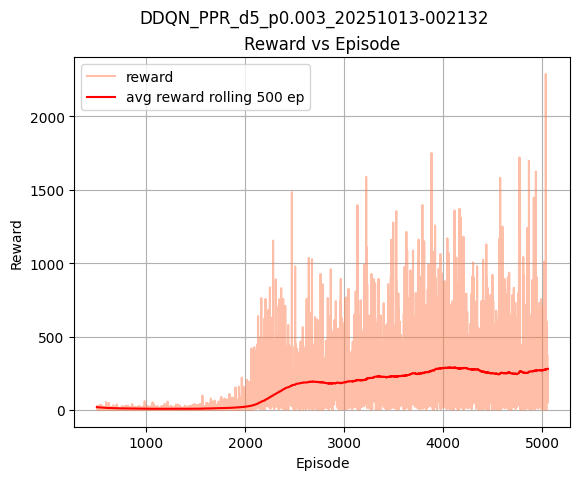

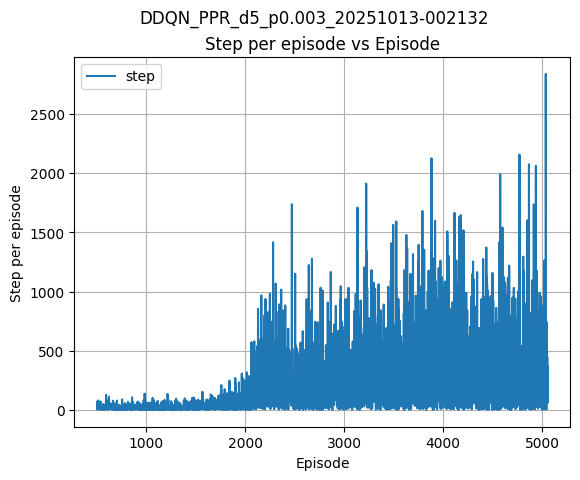

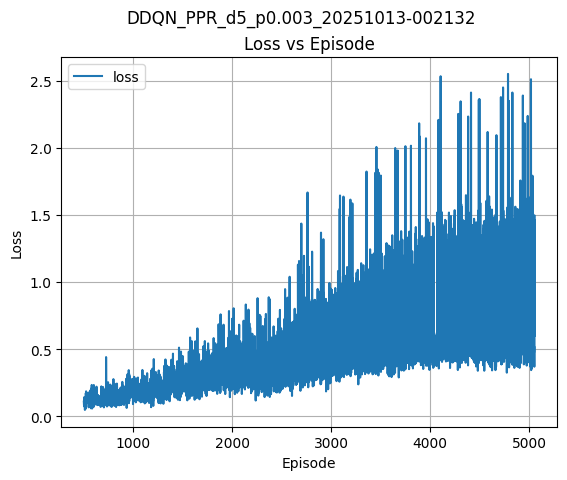

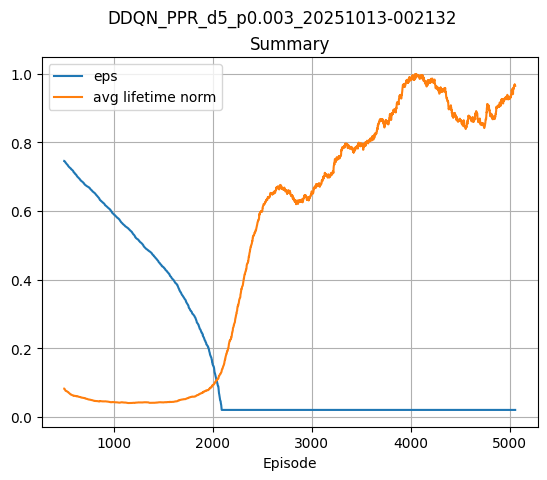

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

## test: p=0.003[0.001] | $\psi$ 0.9 --> 0.02 in 75000

In [ ]:
# primo test di allenamento dell'agente tramite PPR su un ambiente con rumore p 0.003,
# con una libreria basata su [0.001]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "max_episode": 15000,
                "max_steps_per_episode": 1000,
                "eary_stopping": True,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.003,            # mod: 0.003
                    "p_meas": 0.003,            # mod: 0.003
                    "success_threshold": 1450,   # imposto circa la vita media ottenuta by scratch con p 0.003
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.9,             # aggiungo i parametri per PPR 
                    "final_psi": 0.02,
                    "ppr_fraction": 75000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# libreria di policy per PPR
model_paths = [r'runs\DDQN_d5_p0.001_20251010-121427\checkpoints\best_policy_net.pth']
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Library creata con 1 modelli.
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs\DDQN_PPR_d5_p0.003_20251013-135146

---------------------------------
Step : 32461/1000000
Episode : 500
Episode Step : 23 with 17 "reuse" actions
Episode Reward : 7.0
Avg Reward (Last 500 Ep) : 39.86
Best Avg Reward : -inf
Episode Lifetime : 100
Avg Lifetime (Last 500 Ep) : 276.04
Best Avg Lifetime : -inf
Success threshold : 1450
Patience Counter : 0/1000
Metrics : Loss: 0.2063, Epsilon: 0.5758, Psi: 0.5191
Total Training Time : 493.08s
---------------------------------
                                  

---------------------------------
Step : 37321/1000000
Episode : 600
Episode Step : 11 with 3 "reuse" actions
Episode Reward : 7.0
Avg Reward (Last 500 Ep) : 30.64
Best Avg Reward : 39.86
Episode Lifetime : 50
Avg Lifetime (Last 500 Ep) : 217.63
Best Avg Lifetime : 276.04
Success threshold : 1450
Patience Counter : 0/1000
Metrics : Loss: 0.1611, Epsilon: 0.5123, Psi: 0.4621
Total Training Time : 575.62s
---------------------

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

1 ore e 9 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.003_20251013-135146\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]

print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.003_20251013-135146\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 1946
numero step totali : 258309
best avg lifetime (rolling lenght 500) : 1178.56
----------------------------------------------------------


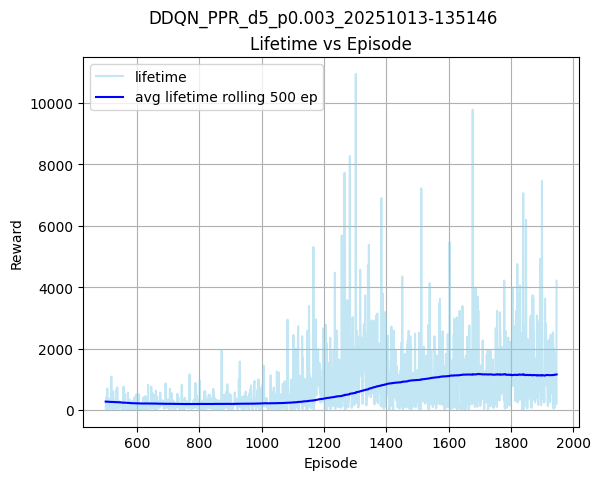

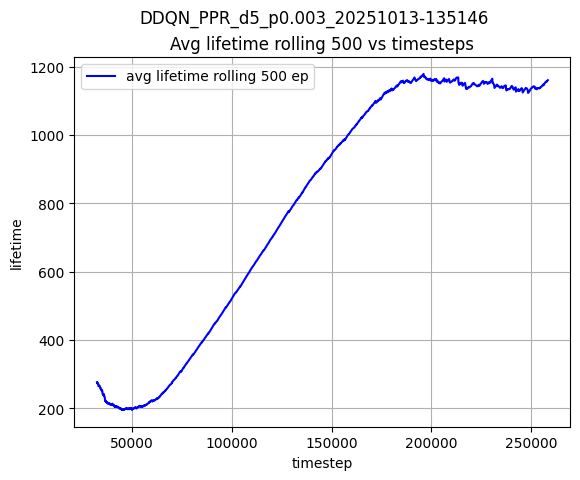

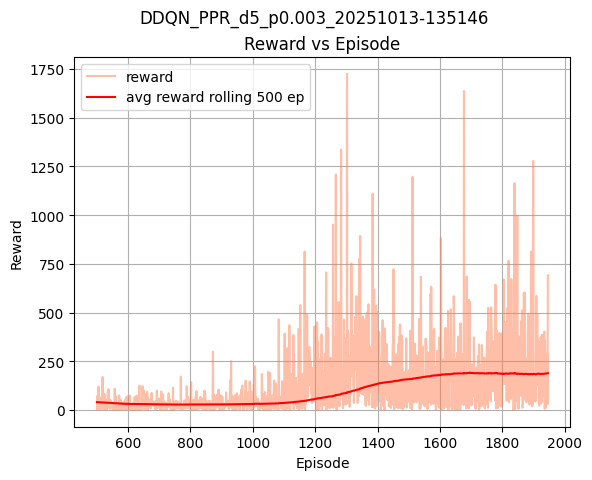

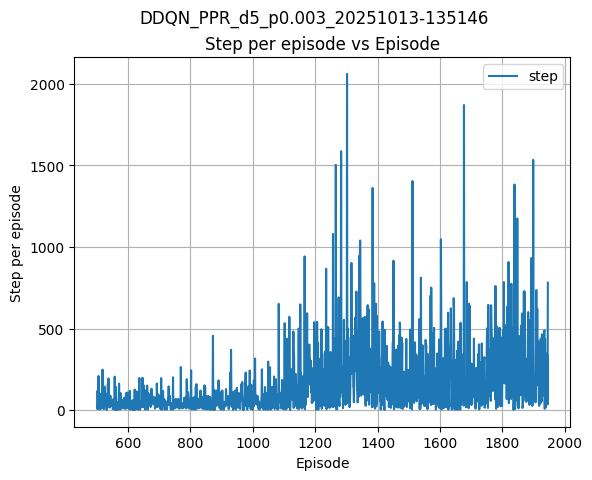

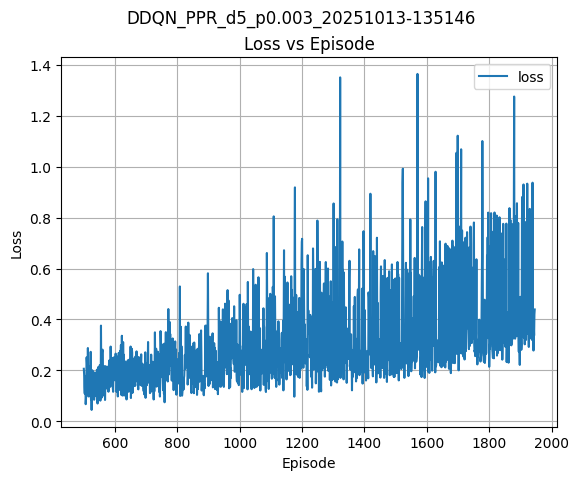

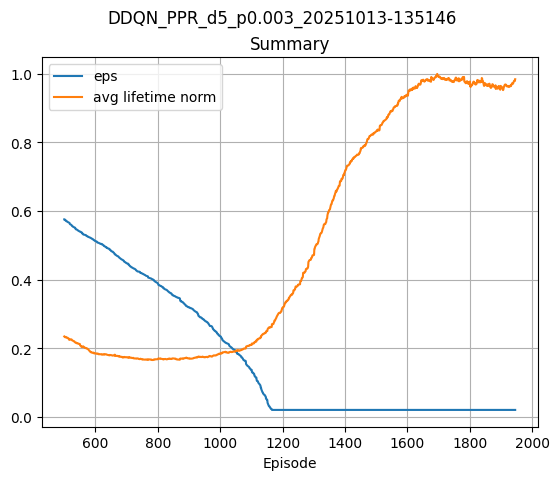

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

## test: p=0.003[0.001] | $\psi$ 0.8 --> 0.1 in 200k steps

In [ ]:
# primo test di allenamento dell'agente tramite PPR su un ambiente con rumore p 0.003,
# con una libreria basata su [0.001]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "max_episode": 15000,
                "max_steps_per_episode": 1000,
                "eary_stopping": True,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.003,            # mod: 0.003
                    "p_meas": 0.003,            # mod: 0.003
                    "success_threshold": 1450,   # imposto circa la vita media ottenuta by scratch con p 0.003
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.8,             # aggiungo i parametri per PPR 
                    "final_psi": 0.1,
                    "ppr_fraction": 200000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# libreria di policy per PPR
model_paths = [r'runs\DDQN_d5_p0.001_20251010-121427\checkpoints\best_policy_net.pth']
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

Library creata con 1 modelli.


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs\DDQN_PPR_d5_p0.003_20251013-152042

---------------------------------
Step : 38564/1000000
Episode : 500
Episode Step : 3 with 3 "reuse" actions
Episode Reward : 0
Avg Reward (Last 500 Ep) : 49.69
Best Avg Reward : -inf
Episode Lifetime : 30
Avg Lifetime (Last 500 Ep) : 336.81
Best Avg Lifetime : -inf
Success threshold : 1450
Patience Counter : 0/1000
Metrics : Loss: 0.2296, Epsilon: 0.4961, Psi: 0.6650
Total Training Time : 544.54s
---------------------------------
                                  
*** Nuovo Best Model salvato! Avg Lifetime: 339.08 ***
*** Nuovo Best Model salvato! Avg Lifetime: 340.02 ***
*** Nuovo Best Model salvato! Avg Lifetime: 341.85 ***
*** Nuovo Best Model salvato! Avg Lifetime: 341.99 ***
*** Nuovo Best Model salvato! Avg Lifetime: 342.97 ***
*** Nuovo Best Model salvato! Avg Lifetime: 343.15 ***
*** Nuovo Best Model salvato! Avg Lifetime: 344.25 ***
*** Nuovo Best Model salvato! Avg Lifetime: 344.3

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

3 ore e 16 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.003_20251013-152042\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]

print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.003_20251013-152042\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 3323
numero step totali : 722909
best avg lifetime (rolling lenght 500) : 1556.8
----------------------------------------------------------


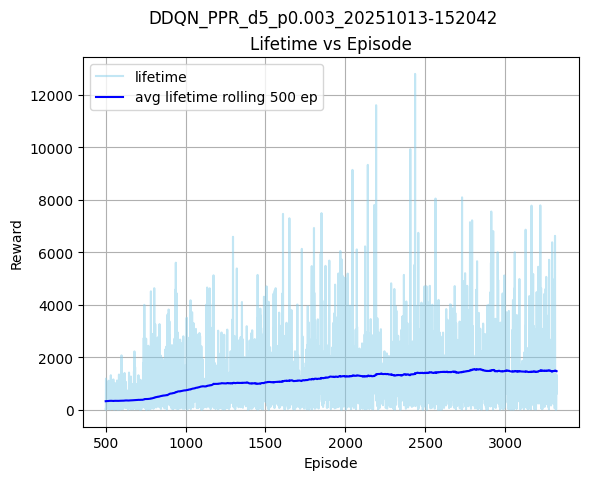

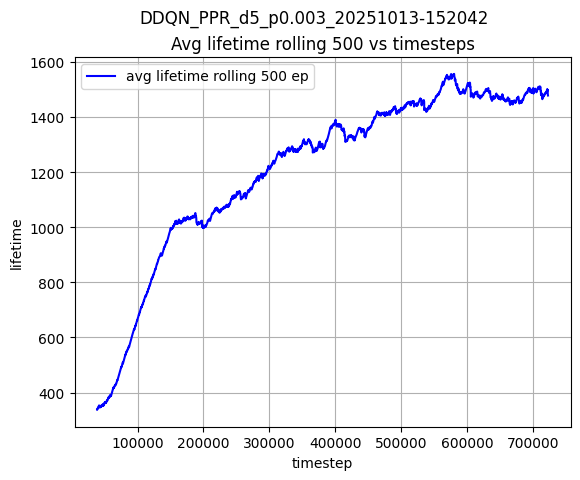

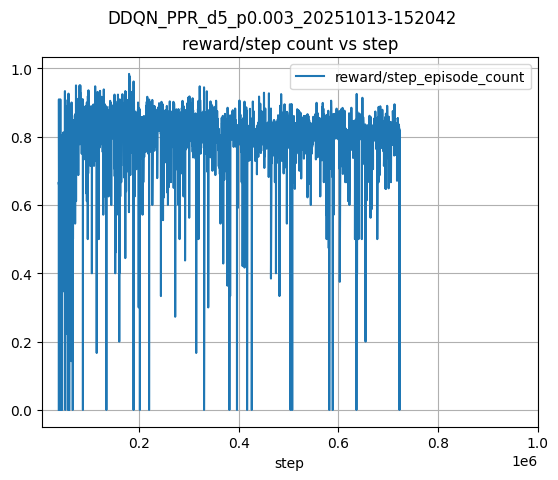

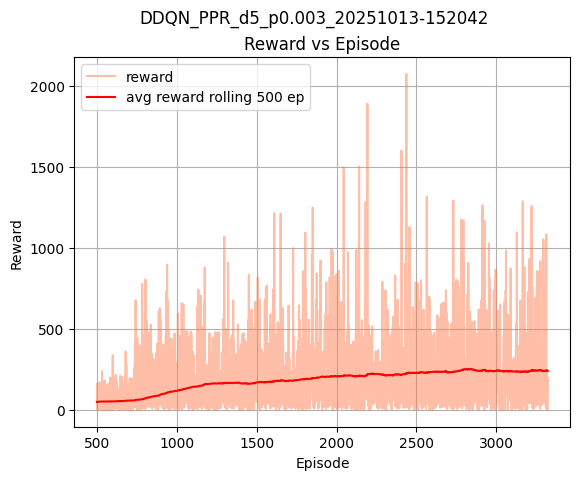

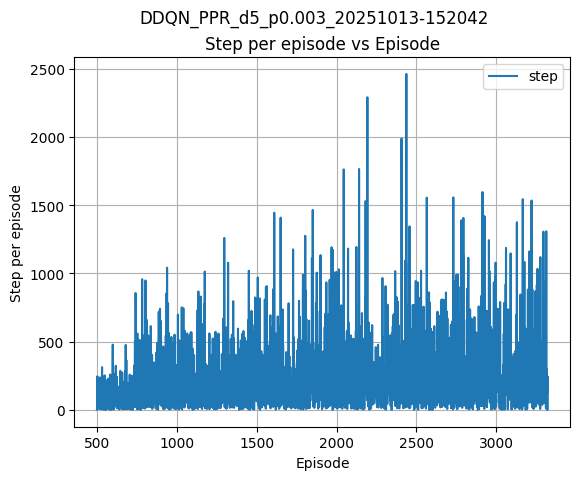

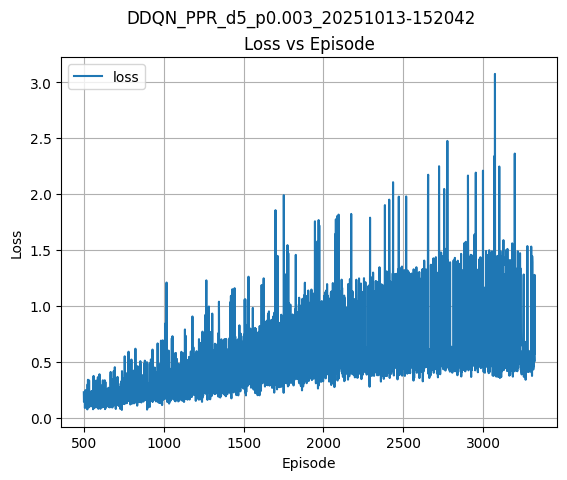

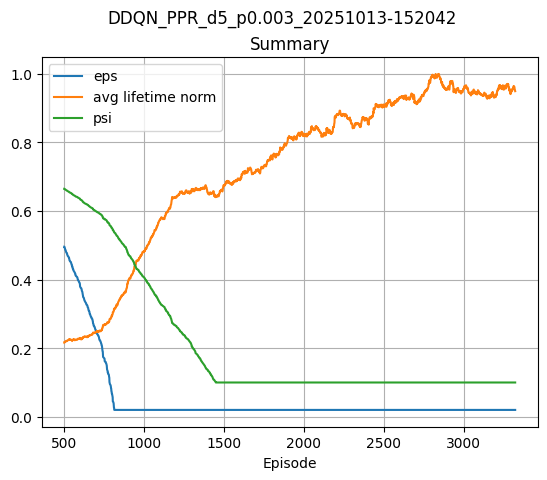

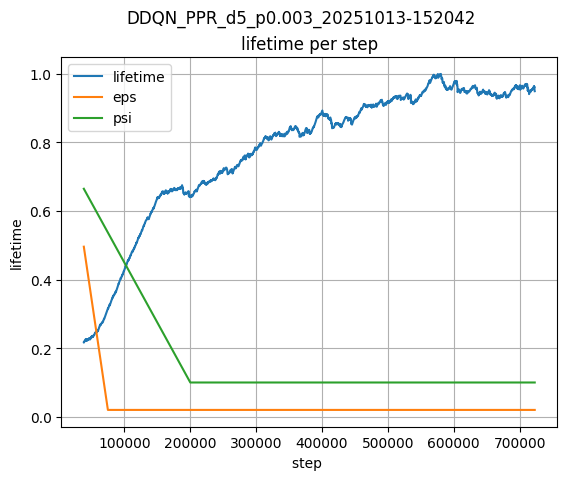

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# add
# rew/step vs step
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, reward/episode_step_count, label='reward/step_episode_count')
ax.set_title('reward/step count vs step')
ax.set_xlabel('step')
ax.set_ylabel('')
ax.set_xlim(right=1e6)
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
ax.plot(episode, psi, label='psi')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

# add
# avg lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime/np.max(avg_lifetime), label='lifetime')
ax.plot(step, eps, label = 'eps')
ax.plot(step, psi, label='psi')
ax.set_title('lifetime per step')
ax.set_xlabel('step ')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()



## test: p=0.005[0.003, 0.001] | $\psi$ 0.85 --> 0.02 225k steps

In [ ]:
# test env 0.005 con una libreria basata su [0.001, 0.003]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "max_episode": 15000,
                "max_steps_per_episode": 1000,
                "eary_stopping": True,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.005,            
                    "p_meas": 0.005,            
                    "success_threshold": 555,   # imposto circa la vita media ottenuta by scratch con p 0.005
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.85,             #### aggiungo i parametri per PPR 
                    "final_psi": 0.02,
                    "ppr_fraction": 225000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# libreria di policy per PPR
model_paths = [r'runs\DDQN_d5_p0.001_20251013-230503\checkpoints\best_policy_net.pth',
               r'runs\DDQN_d5_p0.003_20251014-034106\checkpoints\best_policy_net.pth'
               ]
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

Library creata con 2 modelli.


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs\DDQN_PPR_d5_p0.005_20251014-181024
*** Nuovo Best Model salvato! Avg Lifetime: 260.00 ***
*** Nuovo Best Model salvato! Avg Lifetime: 263.00 ***

---------------------------------
Step : 4928/1000000
Episode : 100
Policy Index k : 1
Episode Step : 147 with 120 "reuse" actions
Episode Reward : 85.0
Avg Reward (Last 500 Ep) : 30.61
Best Avg Reward : 54.00
Episode Lifetime : 395
Avg Lifetime (Last 500 Ep) : 163.15
Best Avg Lifetime : 263.00
Success threshold : 555
Patience Counter : 0/1000
Metrics : Loss: 0.0395, Epsilon: 0.9356, Psi: 0.8318
Total Training Time : 85.98s
---------------------------------
                              

---------------------------------
Step : 9830/1000000
Episode : 200
Policy Index k : 1
Episode Step : 36 with 29 "reuse" actions
Episode Reward : 18.0
Avg Reward (Last 500 Ep) : 29.77
Best Avg Reward : 54.00
Episode Lifetime : 130
Avg Lifetime (Last 500 Ep) : 160.72
Best Avg Lifetime : 263.00
Succes

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

4 ore e 45 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.005_20251014-181024\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]

print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.005_20251014-181024\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 8112
numero step totali : 999867
best avg lifetime (rolling lenght 500) : 527.99
----------------------------------------------------------


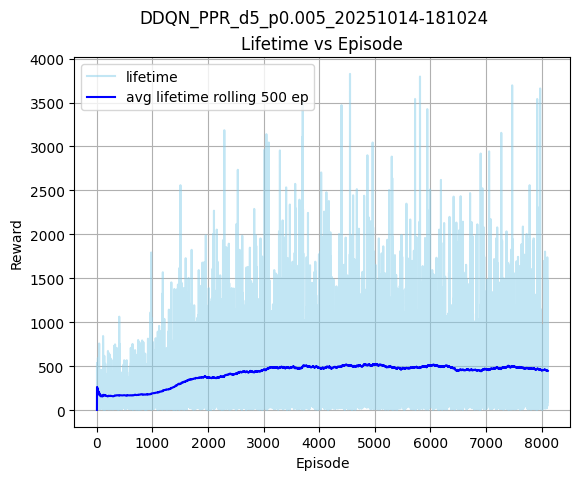

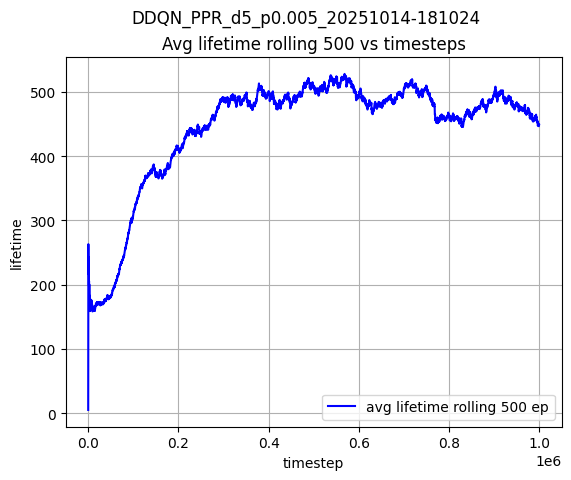

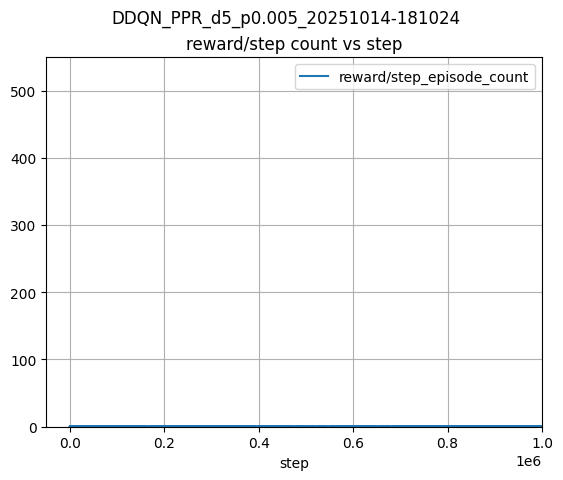

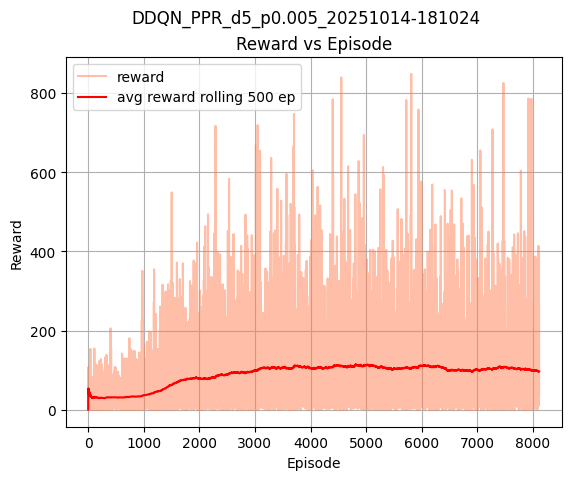

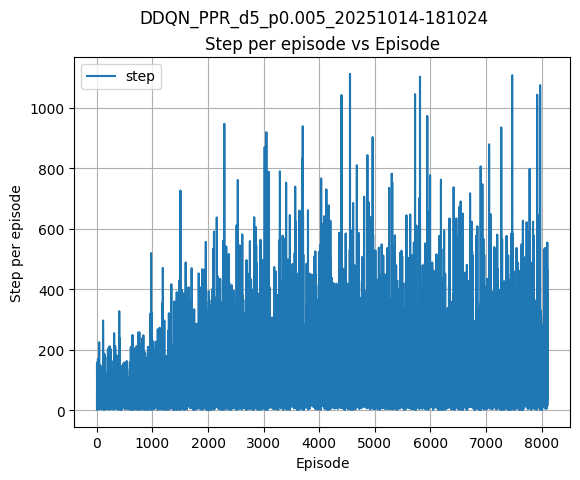

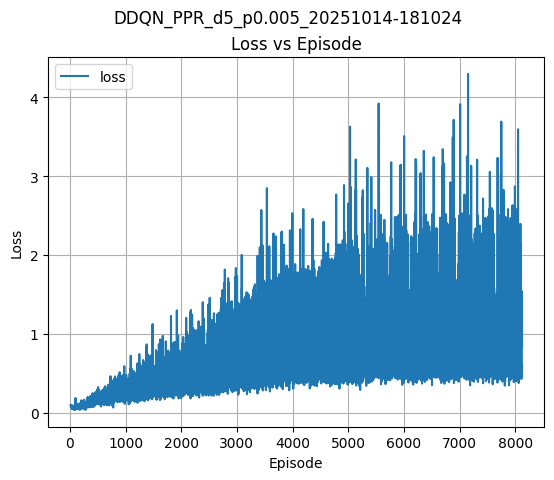

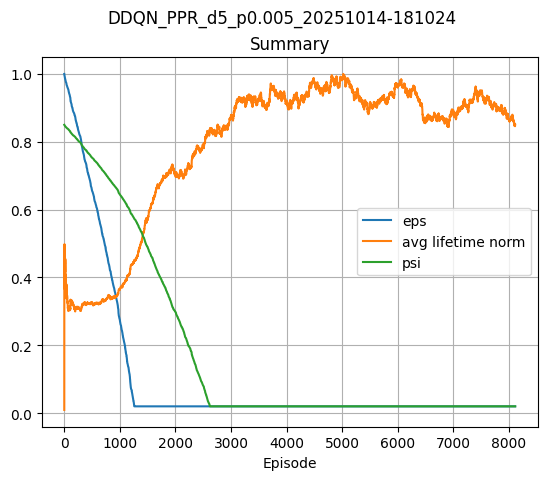

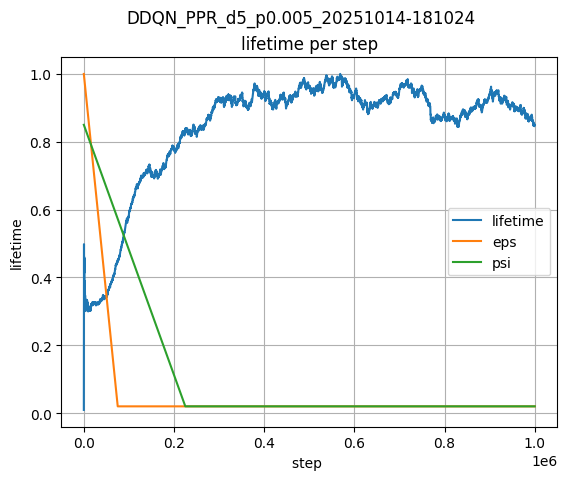

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# add
# rew/step vs step
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, reward/episode_step_count, label='reward/step_episode_count')
ax.set_title('reward/step count vs step')
ax.set_xlabel('step')
ax.set_ylabel('')
ax.set_xlim(right=1e6)
ax.set_ylim(top=550)
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
ax.plot(episode, psi, label='psi')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

# add
# avg lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime/np.max(avg_lifetime), label='lifetime')
ax.plot(step, eps, label = 'eps')
ax.plot(step, psi, label='psi')
ax.set_title('lifetime per step')
ax.set_xlabel('step ')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()



## test: p=0.005[0.003, 0.001] | $\psi$ 0.85 --> 0.02 225k e $\delta\tau$=0.0001

Ho eseguito un test molto breve (meno di 120k steps) giusto per testare la miglior distribuzione delle policy riuse con la modifica del parametro $\delta\tau$. Il risultato, sebbene molto rudimentale, sembra soddisfacente. La run è DDQN_PPR_d5_p0.005_20251015-184852.
Le celle di seguito sono poi state riusate per un test completo.

In [ ]:
# test env 0.005 con una libreria basata su [0.001, 0.003]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "max_episode": 15000,
                "max_steps_per_episode": 1000,
                "eary_stopping": True,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.005,            
                    "p_meas": 0.005,            
                    "success_threshold": 555,   # imposto circa la vita media ottenuta by scratch con p 0.005
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.85,             #### aggiungo i parametri per PPR 
                    "final_psi": 0.02,
                    "ppr_fraction": 225000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# libreria di policy per PPR
model_paths = [r'runs\DDQN_d5_p0.001_20251013-230503\checkpoints\best_policy_net.pth',
               r'runs\DDQN_d5_p0.003_20251014-034106\checkpoints\best_policy_net.pth'
               ]
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

Library creata con 2 modelli.


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs\DDQN_PPR_d5_p0.005_20251015-235326

---------------------------------
Step : 4746/1000000
Episode : 100
Policy Index k : 1
Episode Step : 15 with 12 "reuse" actions
Episode Reward : 7.0
Avg Reward (Last 500 Ep) : 28.75
Best Avg Reward : -inf
Episode Lifetime : 45
Avg Lifetime (Last 500 Ep) : 154.15
Best Avg Lifetime : -inf
Success threshold : 555
Patience Counter : 0/1000
Metrics : Loss: 0.0404, Epsilon: 0.9380, Psi: 0.8325
Total Training Time : 56.05s
---------------------------------
                              

---------------------------------
Step : 8811/1000000
Episode : 200
Policy Index k : 1
Episode Step : 12 with 8 "reuse" actions
Episode Reward : 5.0
Avg Reward (Last 500 Ep) : 26.25
Best Avg Reward : -inf
Episode Lifetime : 50
Avg Lifetime (Last 500 Ep) : 140.35
Best Avg Lifetime : -inf
Success threshold : 555
Patience Counter : 0/1000
Metrics : Loss: 0.1037, Epsilon: 0.8849, Psi: 0.8175
Total Training Time : 110.

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

3 ore e 11 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.005_20251015-235326\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]

# avg_lifetime_500_t = rolling_avg(lifetime, 500, True)
# avg_lifetime_500_f = rolling_avg(lifetime, 500, False)

print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.005_20251015-235326\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 5808
numero step totali : 718179
best avg lifetime (rolling lenght 500) : 585.04
----------------------------------------------------------


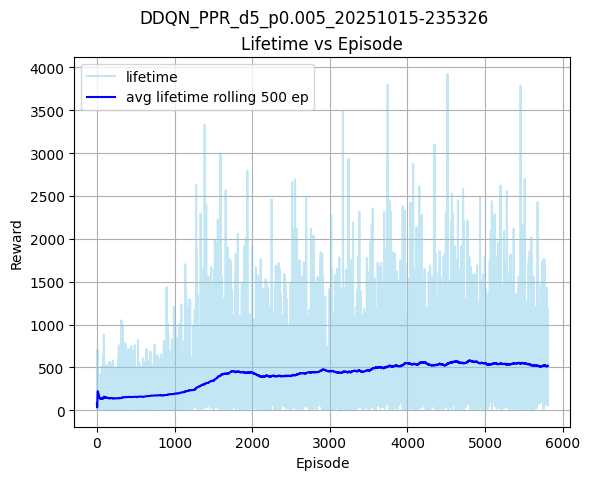

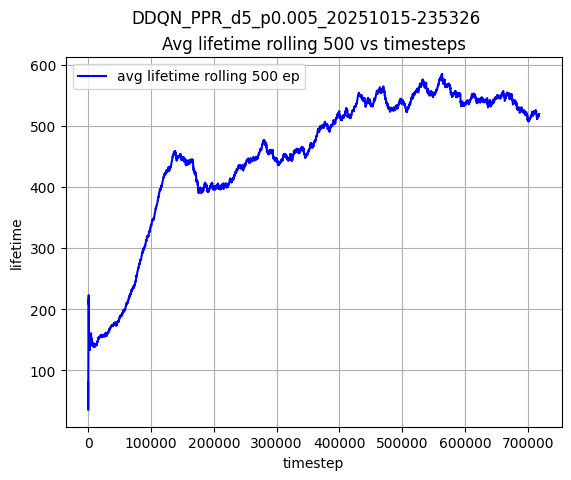

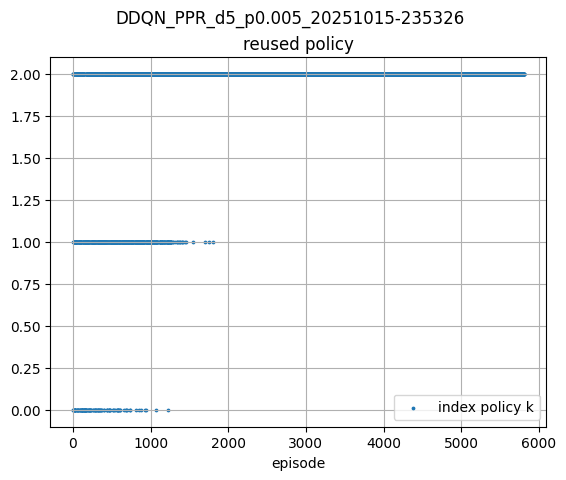

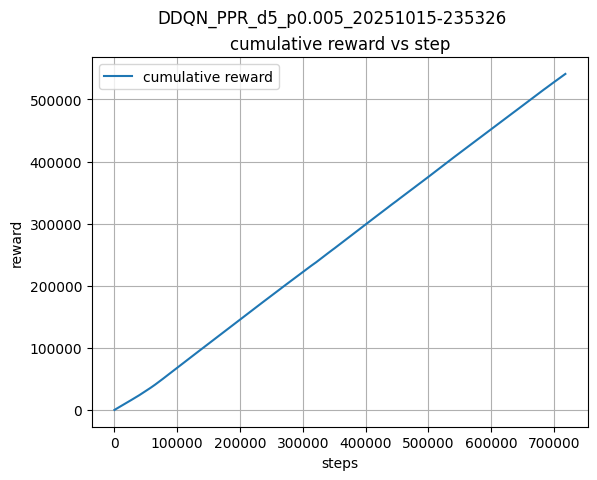

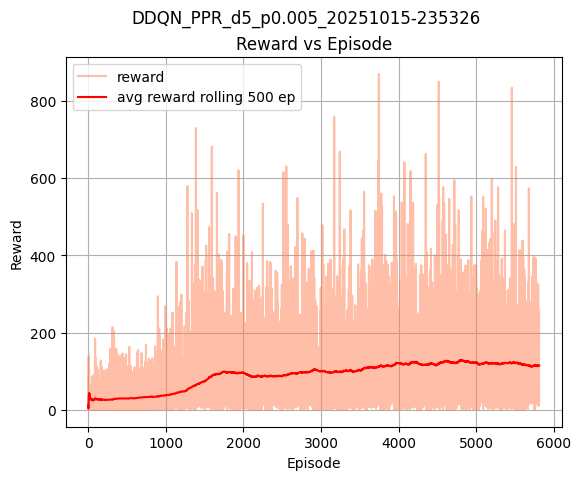

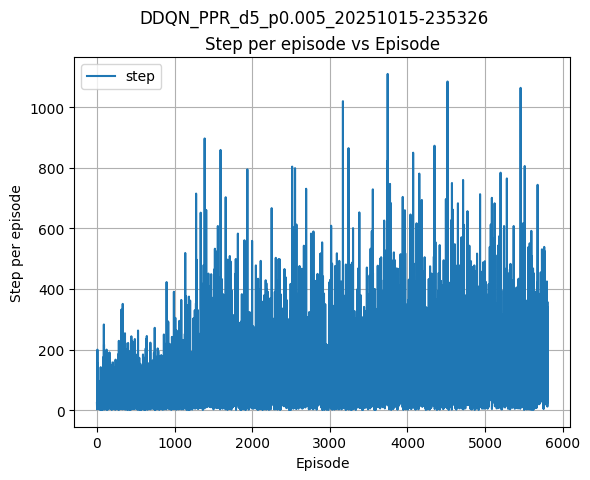

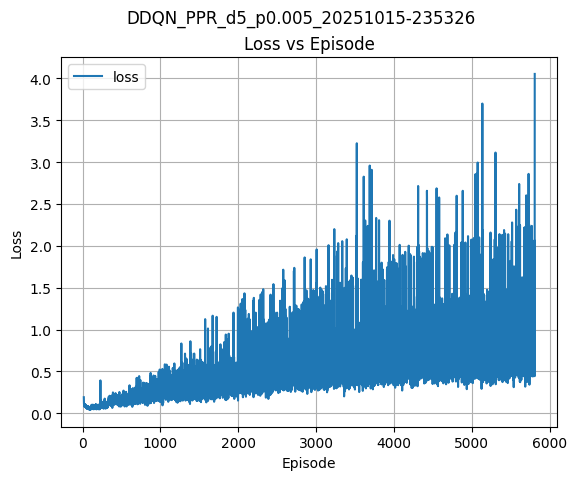

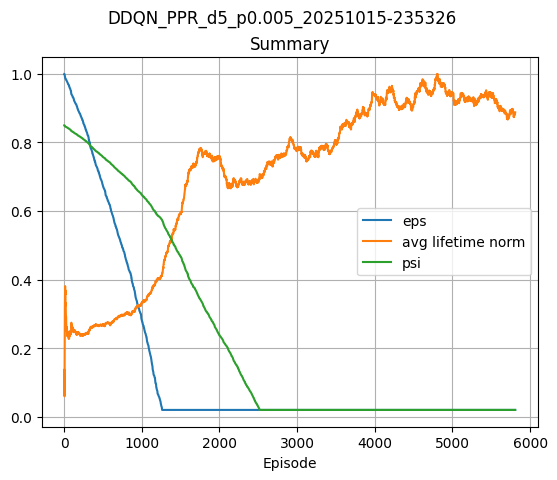

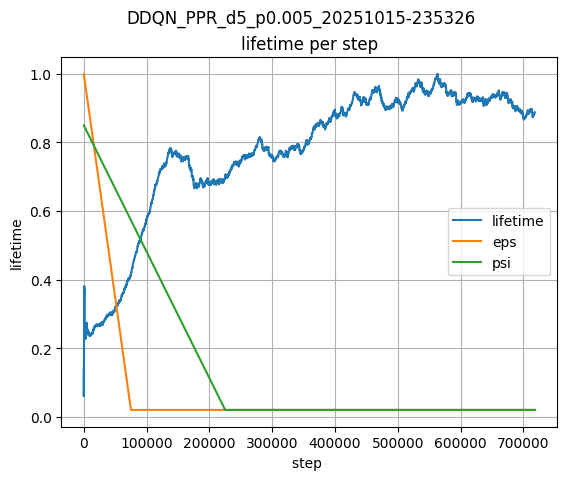

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# add
# k vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.scatter(episode, index_k, s=3, label='index policy k')
ax.set_title('reused policy')
ax.set_xlabel('episode')
ax.set_ylabel('')
ax.legend()
ax.grid()
plt.show()

# add 
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, np.cumsum(reward), label='cumulative reward')
ax.set_title('cumulative reward vs step')
ax.set_xlabel('steps')
ax.set_ylabel('reward')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
ax.plot(episode, psi, label='psi')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

# add
# avg lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime/np.max(avg_lifetime), label='lifetime')
ax.plot(step, eps, label = 'eps')
ax.plot(step, psi, label='psi')
ax.set_title('lifetime per step')
ax.set_xlabel('step ')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()



## test: p=0.005[0.003, 0.001] | $\psi$ 0.85 --> 0.02 175k e $\delta\tau$=0.0001

In [ ]:
# test env 0.005 con una libreria basata su [0.001, 0.003]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.005,            
                    "p_meas": 0.005,            
                    "success_threshold": 555,   # imposto circa la vita media ottenuta by scratch con p 0.005
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.85,             #### aggiungo i parametri per PPR 
                    "final_psi": 0.02,
                    "ppr_fraction": 175000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# libreria di policy per PPR
model_paths = [r'runs\DDQN_d5_p0.001_20251013-230503\checkpoints\best_policy_net.pth',
               r'runs\DDQN_d5_p0.003_20251014-034106\checkpoints\best_policy_net.pth'
               ]
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

Library creata con 2 modelli.


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs\DDQN_PPR_d5_p0.005_20251017-000003

---------------------------------
Step : 3618/1000000
Episode : 100
Policy Index k : 1
Episode Step : 50 with 40 "reuse" actions
Episode Reward : 31.0
Avg Reward (Last 500 Ep) : 20.28
Best Avg Reward : -inf
Episode Lifetime : 185
Avg Lifetime (Last 500 Ep) : 111.95
Best Avg Lifetime : -inf
Success threshold : 555
Patience Counter : 0/1000
Metrics : Loss: 0.0634, Epsilon: 0.9527, Psi: 0.8328
Total Training Time : 41.04s
---------------------------------
                              

---------------------------------
Step : 8372/1000000
Episode : 200
Policy Index k : 2
Episode Step : 103 with 80 "reuse" actions
Episode Reward : 72.0
Avg Reward (Last 500 Ep) : 24.08
Best Avg Reward : -inf
Episode Lifetime : 330
Avg Lifetime (Last 500 Ep) : 129.30
Best Avg Lifetime : -inf
Success threshold : 555
Patience Counter : 0/1000
Metrics : Loss: 0.0611, Epsilon: 0.8906, Psi: 0.8103
Total Training Time 

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

4 ore e 21 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.005_20251017-000003\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]

print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.005_20251017-000003\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 8023
numero step totali : 999989
best avg lifetime (rolling lenght 500) : 551.28
----------------------------------------------------------


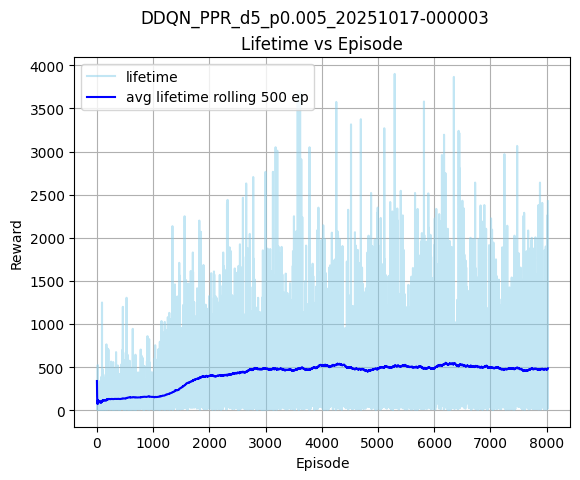

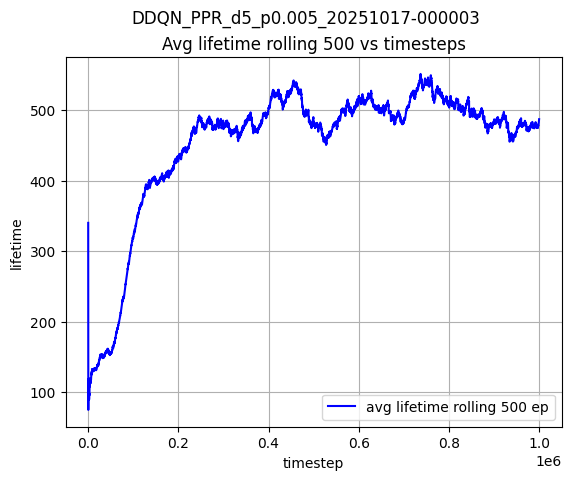

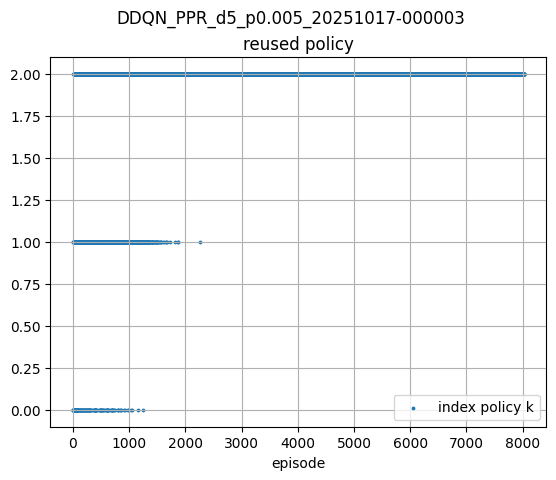

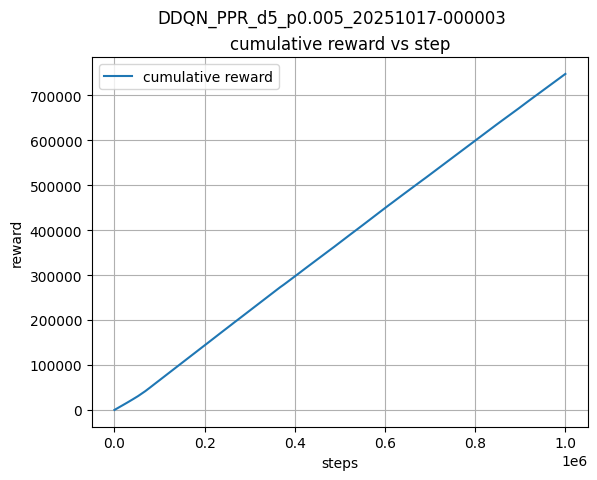

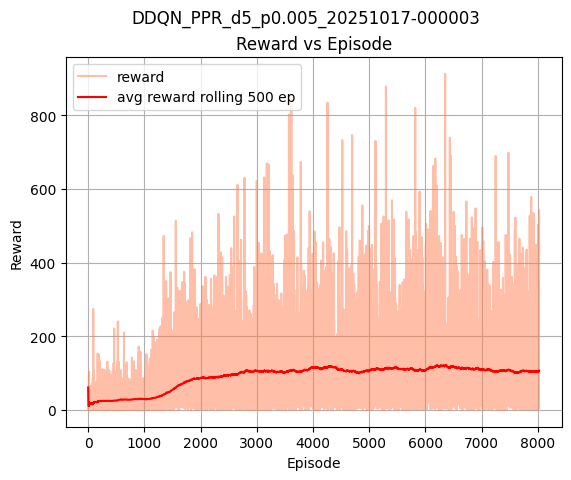

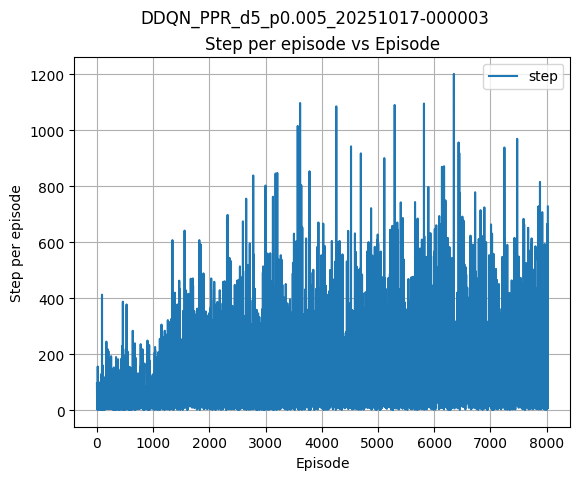

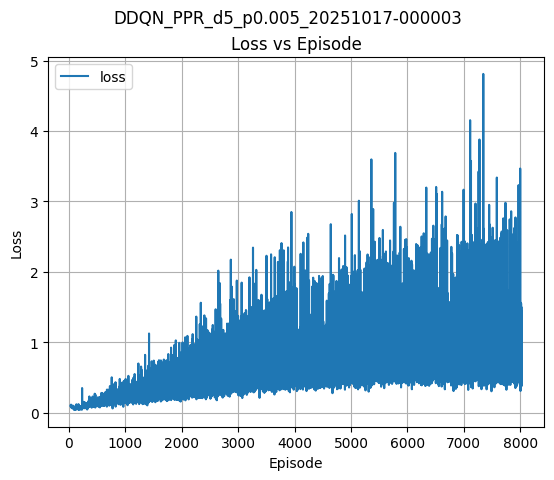

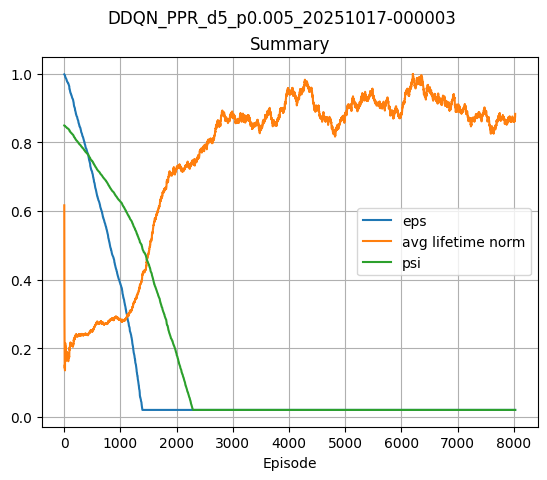

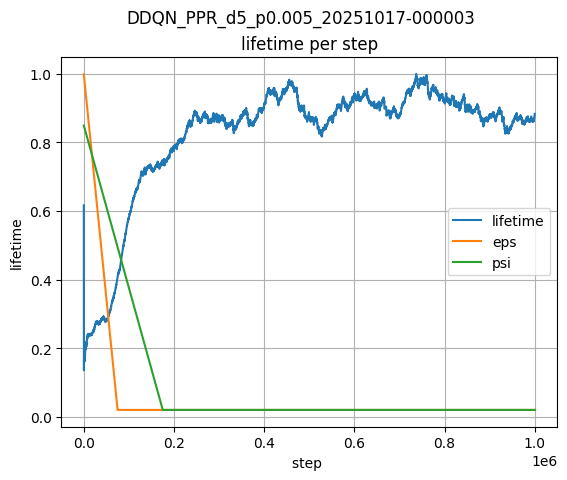

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# add
# k vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.scatter(episode, index_k, s=3, label='index policy k')
ax.set_title('reused policy')
ax.set_xlabel('episode')
ax.set_ylabel('')
ax.legend()
ax.grid()
plt.show()

# add 
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, np.cumsum(reward), label='cumulative reward')
ax.set_title('cumulative reward vs step')
ax.set_xlabel('steps')
ax.set_ylabel('reward')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
ax.plot(episode, psi, label='psi')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

# add
# avg lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime/np.max(avg_lifetime), label='lifetime')
ax.plot(step, eps, label = 'eps')
ax.plot(step, psi, label='psi')
ax.set_title('lifetime per step')
ax.set_xlabel('step ')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()



## test: p=0.003[0.001] | $\psi$ 0.85 --> 0.02 175k e $\delta\tau$=0.0001

In [ ]:
# ripristino prima del codice successivo --> utile per sessioni training avviate consecutive in automatico
del agent
del policy_net
del target_net
del memory
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()
print("Pulizia della memoria effettuata. Le variabili principali sono state rimosse.")

Pulizia della memoria effettuata. Le variabili principali sono state rimosse.


In [ ]:
# test env 0.003 con una libreria basata su [0.001]

fixed_configs = {"d": 5,
                "error_model": "X",                 
                "use_Y": False,
                "volume_depth": 5,
                "train_freq": 1,
                "print_freq": 100,      
                "batch_size": 64,       
                "buffer_size": 50000,
                "rolling_average_length": 500,  
                "max_timesteps": 1000000,
                "stopping_patience": 1000,   
                "c_layers": [[64,3,2],[32,2,1],[32,2,1]],
                "ff_layers": [[512,0.2]],
                "dueling": True,
                "masked_greedy": False,
                "static_decoder": True}

variable_configs = {"p_phys": 0.003,            
                    "p_meas": 0.003,            
                    "success_threshold": 1500,   # imposto circa la vita media ottenuta by scratch con p 0.005
                    "learning_starts": 1000,             
                    "learning_rate": 0.0001,  
                    "max_eps": 1.0,
                    "final_eps": 0.02,      
                    "exploration_fraction": 75000,
                    "max_psi": 0.85,             #### aggiungo i parametri per PPR 
                    "final_psi": 0.02,
                    "ppr_fraction": 175000,                       
                    "target_network_update_freq":5000, 
                    "gamma": 0.99}

all_configs = {}
for key in fixed_configs.keys():
    all_configs[key] = fixed_configs[key]
for key in variable_configs.keys():
    all_configs[key] = variable_configs[key]


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
# 1 - decoder statico --> nuovo decoder
static_decoder_path = os.path.join(os.getcwd(),"referee_decoders/static_decoder_d5_X_p5.pth")
static_decoder = PyTorchStaticDecoder() 
static_decoder.load_state_dict(torch.load(static_decoder_path)) 
static_decoder.eval()
print('static_decoder caricato!')

# 2 - ambiente 
env = Surface_Code_Environment_Multi_Decoding_Cycles(
    d=all_configs["d"],
    p_phys=all_configs["p_phys"],
    p_meas=all_configs["p_meas"],
    error_model=all_configs["error_model"],
    volume_depth=all_configs["volume_depth"],
    static_decoder=static_decoder 
)

# 3 - agente e suoi componenti
input_shape = env.observation_space.shape
num_actions = env.num_actions

# reti neurali 
policy_net = ConvNetRL(all_configs["c_layers"], all_configs["ff_layers"], input_shape, num_actions, dueling=all_configs["dueling"]).to(device)
target_net = copy.deepcopy(policy_net).to(device)
target_net.eval()

# inizializzo l'Optimizer 
optimizer = optim.Adam(policy_net.parameters(), lr=all_configs["learning_rate"])

# memoria e policy
memory = ReplayBuffer(all_configs["buffer_size"])

policy = LinearAnnealedEpsGreedyPolicy(
    value_max=all_configs["max_eps"], 
    value_min=all_configs["final_eps"], 
    nb_steps=all_configs["exploration_fraction"],
    masked_greedy=all_configs["masked_greedy"]
)

# agente DDQN
agent = PyTorchDDQNAgent(policy_net, target_net, optimizer, memory, all_configs, device) 

print("Inizializzazione di tutti i componenti completata.")
print(f"Policy Net input shape: {input_shape}, Output: {num_actions}")


static_decoder caricato!
Inizializzazione di tutti i componenti completata.
Policy Net input shape: (6, 11, 11), Output: 26


In [ ]:
# libreria di policy per PPR
model_paths = [r'runs\DDQN_d5_p0.001_20251013-230503\checkpoints\best_policy_net.pth'
               ]
library = make_library(model_paths, policy_net, device)
print(f'Library creata con {len(library)} modelli.')

Library creata con 1 modelli.


In [ ]:
# train eseguito train_wit_ppr
timeS = time.time()
train_with_ppr(agent, env, policy, policy_net, memory, library, all_configs, device=device)
timeF = time.time()
dT = timeF-timeS
print(f'durata {dT}s')

Inizio Addestramento con PPR su 1000000 passi. Log in: runs\DDQN_PPR_d5_p0.003_20251017-042142

---------------------------------
Step : 5659/1000000
Episode : 100
Policy Index k : 1
Episode Step : 98 with 80 "reuse" actions
Episode Reward : 69.0
Avg Reward (Last 500 Ep) : 36.39
Best Avg Reward : -inf
Episode Lifetime : 405
Avg Lifetime (Last 500 Ep) : 256.00
Best Avg Lifetime : -inf
Success threshold : 1500
Patience Counter : 0/1000
Metrics : Loss: 0.0524, Epsilon: 0.9261, Psi: 0.8232
Total Training Time : 64.16s
---------------------------------
                              

---------------------------------
Step : 13571/1000000
Episode : 200
Policy Index k : 1
Episode Step : 6 with 3 "reuse" actions
Episode Reward : 0
Avg Reward (Last 500 Ep) : 43.70
Best Avg Reward : -inf
Episode Lifetime : 15
Avg Lifetime (Last 500 Ep) : 302.10
Best Avg Lifetime : -inf
Success threshold : 1500
Patience Counter : 0/1000
Metrics : Loss: 0.0907, Epsilon: 0.8227, Psi: 0.7856
Total Training Time : 17

In [ ]:
durata = dT/3600
durataH = np.floor(durata)
durataM =  np.floor((durata - durataH)*60)
print(f'{durataH:.0f} ore e {durataM:.0f} min')

3 ore e 54 min


### valutazione training log

In [ ]:
# estrazione log di allenamento 
TRAINING_LOG_PATH =  r'runs\DDQN_PPR_d5_p0.003_20251017-042142\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
# estraggo da history tutte le liste di log ottenuti con train_with_ppr : 
step = np.array([log_data['step'] for log_data in training_history])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
episode_step_count = np.array([log_data['episode_step_count'] for log_data in training_history])
reused_action = np.array([log_data['reuse_actions'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
std_reward = np.array([log_data['reward_std'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])
std_lifetime = np.array([log_data['lifetime_std'] for log_data in training_history])
loss = np.array([log_data['loss'] for log_data in training_history])
eps = np.array([log_data['epsilon'] for log_data in training_history])
psi = np.array([log_data['psi'] for log_data in training_history])
run = TRAINING_LOG_PATH.split('\\')[1]

print('----------------------------------------------------------')
print(f'numero episodi totali : {episode[-1]}')
print(f'numero step totali : {step[-1]}')
print(f'best avg lifetime (rolling lenght {all_configs['rolling_average_length']}) : {np.max(avg_lifetime)}')
print('----------------------------------------------------------')


Contenuto di runs\DDQN_PPR_d5_p0.003_20251017-042142\training_history.json estratto con successo:
----------------------------------------------------------
numero episodi totali : 4111
numero step totali : 999976
best avg lifetime (rolling lenght 500) : 1663.36
----------------------------------------------------------


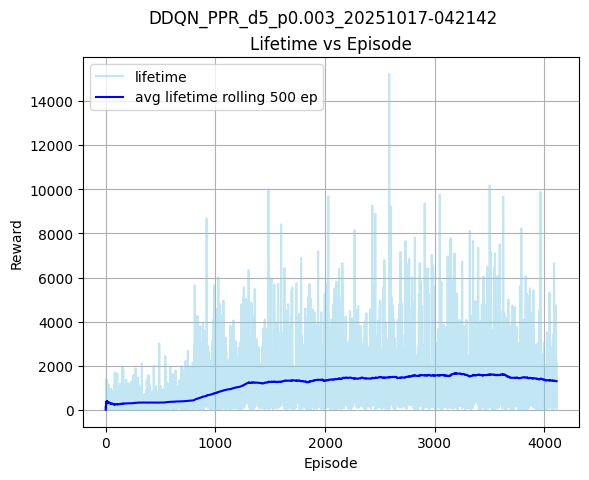

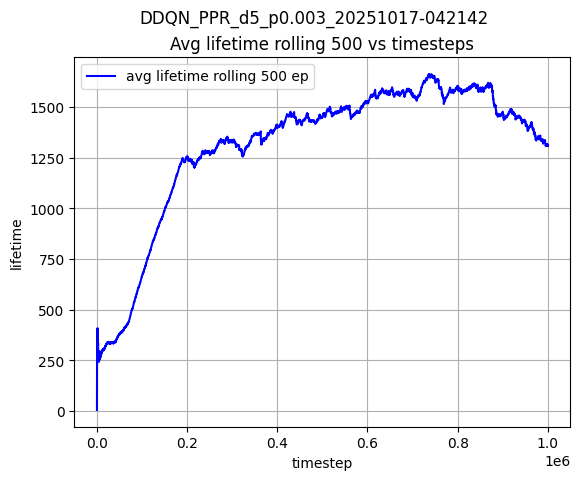

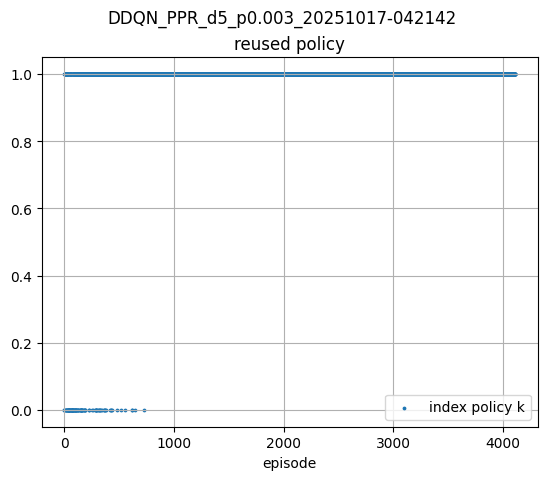

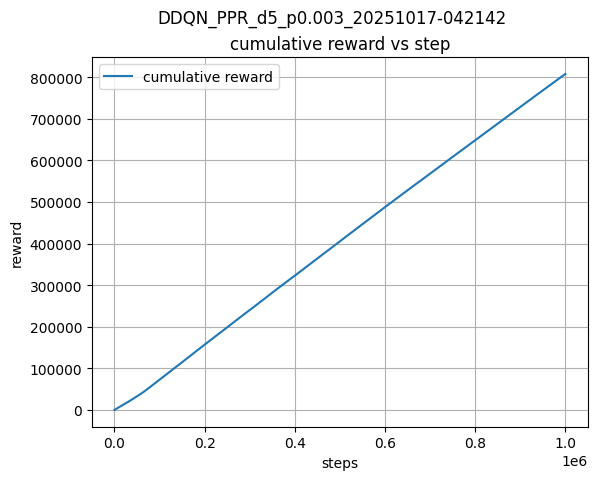

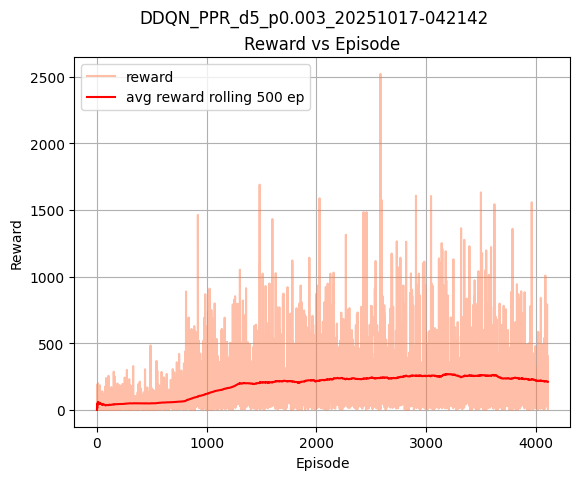

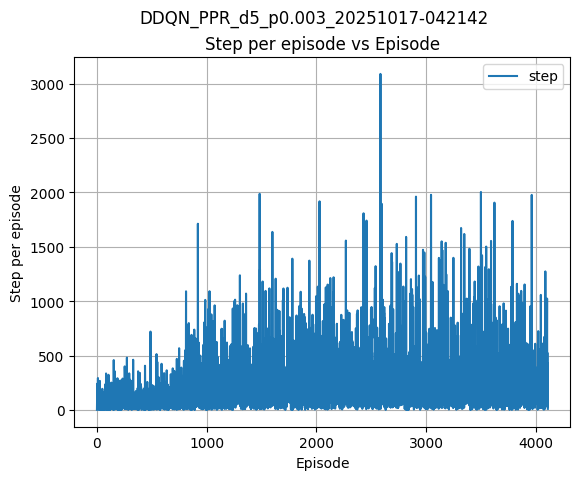

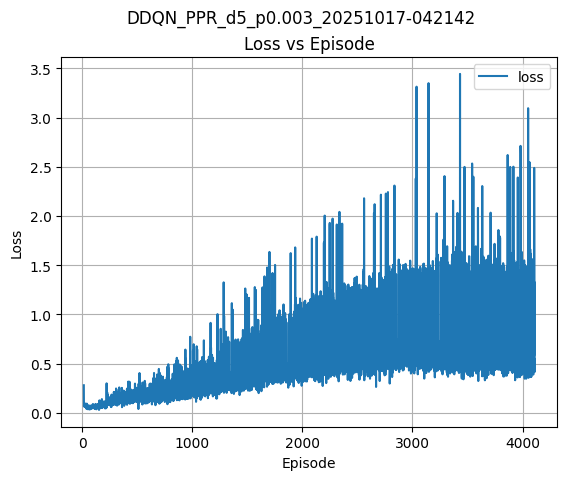

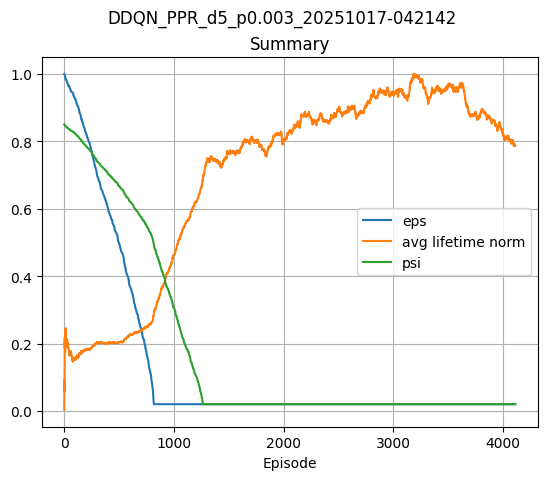

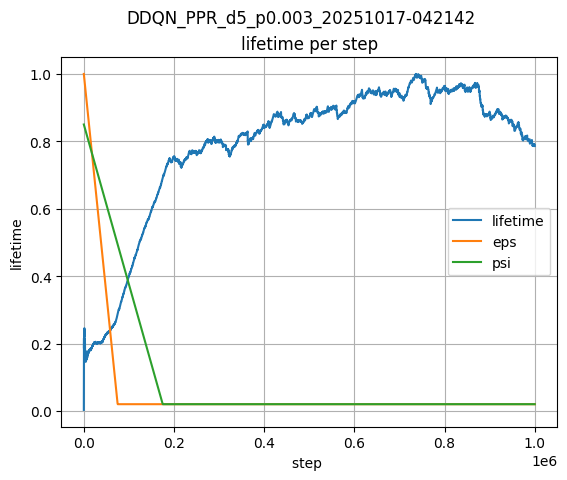

In [ ]:
# grafici
# lifetime vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_lifetime, yerr=std_lifetime, label='avg lifetime rolling 500 ep', c='b', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, lifetime, label='lifetime', alpha= 0.5,c='skyblue')
ax.plot(episode, avg_lifetime, label='avg lifetime rolling 500 ep', c='b')
ax.set_title('Lifetime vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# avg_lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime, c='b', label='avg lifetime rolling 500 ep')
ax.set_title('Avg lifetime rolling 500 vs timesteps')
ax.set_xlabel('timestep')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

# add
# k vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.scatter(episode, index_k, s=3, label='index policy k')
ax.set_title('reused policy')
ax.set_xlabel('episode')
ax.set_ylabel('')
ax.legend()
ax.grid()
plt.show()

# add 
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, np.cumsum(reward), label='cumulative reward')
ax.set_title('cumulative reward vs step')
ax.set_xlabel('steps')
ax.set_ylabel('reward')
ax.legend()
ax.grid()
plt.show()

# reward vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
# ax.errorbar(episode, avg_reward, yerr=std_reward, label='avg reward rolling 500 ep', c='r', ecolor='lightgray', elinewidth=1, capsize=0)
ax.plot(episode, reward, label='reward', alpha= 0.5,c='coral')
ax.plot(episode, avg_reward, label='avg reward rolling 500 ep', c='r')
ax.set_title('Reward vs Episode')
ax.set_xlabel('Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
ax.grid()
plt.show()

# step count episode vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, episode_step_count, label='step')
ax.set_title('Step per episode vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Step per episode')
ax.legend()
ax.grid()
plt.show()

# loss vs episode
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, loss, label='loss')
ax.set_title('Loss vs Episode')
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.legend()
ax.grid()
plt.show()

# summary
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(episode, eps, label='eps')
ax.plot(episode, avg_lifetime/np.max(avg_lifetime), label ='avg lifetime norm')
ax.plot(episode, psi, label='psi')
# ax.plot(episode, loss/np.max(loss), alpha=0.3, label='loss')
ax.set_title('Summary')
ax.set_xlabel('Episode')
ax.legend()
ax.grid()
plt.show()

# add
# avg lifetime vs timestep
fig, ax = plt.subplots()
fig.suptitle(run)
ax.plot(step, avg_lifetime/np.max(avg_lifetime), label='lifetime')
ax.plot(step, eps, label = 'eps')
ax.plot(step, psi, label='psi')
ax.set_title('lifetime per step')
ax.set_xlabel('step ')
ax.set_ylabel('lifetime')
ax.legend()
ax.grid()
plt.show()

